<a href="https://colab.research.google.com/github/amrtx7/customer_churn_prediction/blob/main/customer_churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub[pandas-datasets]

import kagglehub
import pandas as pd
import os

# Download the dataset
path = kagglehub.dataset_download(
    "rjmanoj/credit-card-customer-churn-prediction"
)

# Inspect downloaded files
for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

100%|██████████| 262k/262k [00:00<00:00, 509kB/s]

Extracting files...
/root/.cache/kagglehub/datasets/rjmanoj/credit-card-customer-churn-prediction/versions/1/Churn_Modelling.csv


In [2]:
# Find CSV files
csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

# Load the first CSV
df = pd.read_csv(csv_files[0])

print(df.head())
print(df.shape)

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4         790

# Customer Churn Prediction - Binary Classification

In [18]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [5]:
df['Exited'].value_counts()
#  imbalance classification - as the end goal is to make a ann, we are not focusing on making the perfect model


,count
Exited,
0,7963
1,2037


In [6]:
# removing unecessary columns
df = df.drop(columns=["RowNumber", 'CustomerId', 'Surname'])

In [15]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [16]:
#  one hot encoding the categorical values
df = pd.get_dummies(df,columns = ['Geography', 'Gender'], drop_first=True)

KeyError: "None of [Index(['Geography', 'Gender'], dtype='object')] are in the [columns]"

In [19]:
X = df.drop(columns=['Exited'])
y = df['Exited']
# X -> ANN -> y


from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=1)

In [20]:
X


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,True,False,True


In [21]:
y

,Exited
0,1
1,0
2,1
3,0
4,0
...,...
9995,0
9996,0
9997,1
9998,1


In [22]:
# Time to scale down big values

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [23]:
X_train_scaled

array([[-0.23082038, -0.94449979, -0.70174202, ...,  1.71490137,
        -0.57273139,  0.91509065],
       [-0.25150912, -0.94449979, -0.35520275, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [-0.3963303 ,  0.77498705,  0.33787579, ...,  1.71490137,
        -0.57273139, -1.09278791],
       ...,
       [ 0.22433188,  0.58393295,  1.3774936 , ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 0.13123255,  0.01077067,  1.03095433, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 1.1656695 ,  0.29735181,  0.33787579, ...,  1.71490137,
        -0.57273139,  0.91509065]], shape=(8000, 11))

In [25]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [41]:
model = Sequential()

# A Dense layer is a fully connected layer. Every neuron in one layer connects to every neuron in the next layer.
model.add(Dense(11,activation = 'relu',input_dim=11))
model.add(Dense(11,activation = 'relu',input_dim=11))
model.add(Dense(1,activation = 'sigmoid')) # sigmoid produces output between 0 and 1


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [42]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
model.compile(loss='binary_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [70]:
history = model.fit(X_train_scaled,y_train,epochs=10,validation_split=0.2)
# If your original dataset has 10,000 rows:
# - Training set: 8,000 rows.
# - Testing set: 2,000 rows.
# - From the 8,000 training rows:
#   - 6,400 for actual training.
#   - 1,600 for validation.
# What is validation used for?
# - Training data: The model learns its weights.
# - Validation data: Checks performance during training and helps monitor overfitting.
# - Testing data: Evaluates the final model on unseen data.
# The test set should not be used to tune the model.

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8453 - loss: 0.3712 - val_accuracy: 0.8369 - val_loss: 0.3695
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8484 - loss: 0.3688 - val_accuracy: 0.8381 - val_loss: 0.3685
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8492 - loss: 0.3656 - val_accuracy: 0.8425 - val_loss: 0.3653
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8489 - loss: 0.3641 - val_accuracy: 0.8400 - val_loss: 0.3642
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8503 - loss: 0.3618 - val_accuracy: 0.8419 - val_loss: 0.3646
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8530 - loss: 0.3604 - val_accuracy: 0.8425 - val_loss: 0.3636
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8539 - loss: 0.3584 - val_accuracy: 0.8450 - val_loss: 0.3615
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8541 - loss: 0.3576 - val_accuracy: 0.

In [71]:
model.layers[0].get_weights()
# This returns two arrays:
# 1. Weight matrix.
# 2. Bias vector.
# For your architecture, the first layer has 11 input features and 11 neurons.

# Therefore:
# W{ shape}=(11,11)
# b{ shape}=(11,)

[array([[-2.9998124e-01, -1.3390032e-02,  5.2379109e-02,  2.8111944e-01,
          1.4665017e-02,  7.9616874e-02, -9.0589888e-02,  2.6505333e-01,
          1.5244834e-01, -1.1877313e-01,  2.9749414e-01],
        [-5.3342992e-01, -2.7068844e-02, -6.5846109e-01, -1.0270237e+00,
          5.7641548e-01,  3.6110145e-01,  3.9532956e-01, -9.5816404e-01,
          4.0231133e-01, -3.4398323e-01,  6.2659776e-01],
        [-3.3653840e-01, -5.9113009e-03, -5.1964466e-02,  4.1075474e-01,
          6.8641894e-02, -6.3587344e-01, -2.5573748e-01, -3.5588318e-01,
          1.0317720e-01,  3.3756125e-01, -7.8229934e-02],
        [ 1.9443810e-01, -4.9712253e-01, -4.1677377e-01, -1.1703510e-01,
         -9.6669890e-02,  1.5027705e-01,  2.1803996e-01,  4.1969225e-01,
         -3.1345072e-01,  1.9139640e-01,  3.3777156e-01],
        [-6.4600956e-01, -1.3094693e+00, -1.7552936e-01, -4.3917920e-02,
          4.2420864e-01,  5.2606684e-01,  6.0409683e-01, -1.5669395e-01,
          1.6272918e+00, -3.8464203e-0

In [72]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [73]:
import numpy as np
y_pred = np.where(y_log>0.5,1,0)

In [74]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    accuracy_score
)

print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_log))

0.855
[[1533   52]
 [ 238  177]]
              precision    recall  f1-score   support

           0       0.87      0.97      0.91      1585
           1       0.77      0.43      0.55       415

    accuracy                           0.85      2000
   macro avg       0.82      0.70      0.73      2000
weighted avg       0.85      0.85      0.84      2000

ROC-AUC: 0.851727414389419


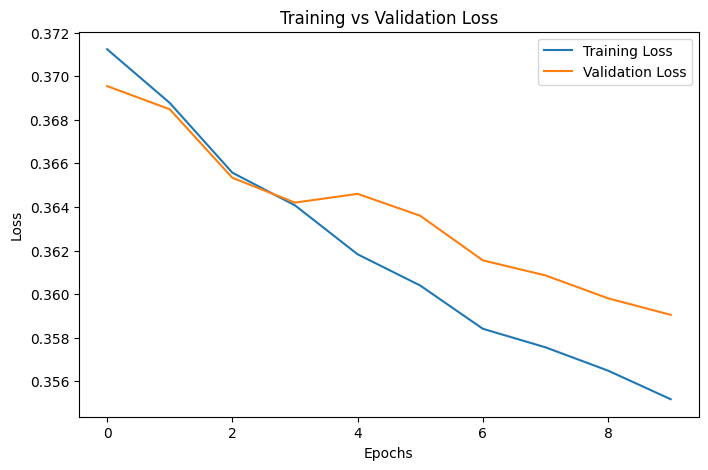

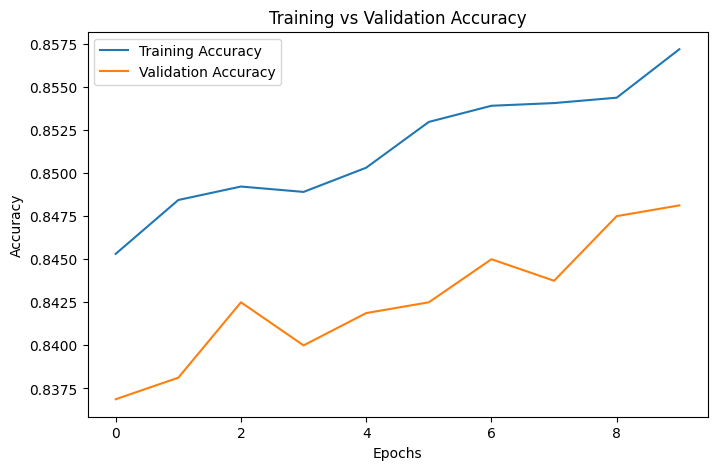

In [75]:
import matplotlib.pyplot as plt

# Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

# Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.show()